# 2  Preprocessing and Cleaning

The shapes of the database differ strongly in how finely they are sampled, from 16 to 98,256 vertices, and in how
clean their geometry is. Both properties influence the features that are extracted in the next step. Descriptors that are
computed on mesh vertices depend on the number and the distribution of these vertices, and descriptors that are based on
areas, volumes or surface normals require valid, consistently oriented surfaces. This section therefore measures what the
database contains and prepares it for feature extraction: every shape is cleaned and brought to a common sampling
resolution, while its geometry is left unchanged.

The section follows the sub-steps of the assignment. Section 2.1 defines the measurements that are made on a single
shape. Section 2.2 applies them to the complete database of 2,483 shapes in 69 classes, describes the
distribution of the vertex and face counts, identifies outliers and quantifies the quality of the raw meshes. Section 2.3
describes how every shape is cleaned, re-oriented and resampled, evaluates this on a reduced and on the complete database,
and discusses the few shapes for which the standard resampling method fails. The verification of the processed database
(Section 2.4) and the normalization of position and size (Section 2.5) follow.

## Notation

A **mesh** is $M=(V,F)$ with **vertices** $V=\{v_i\}_{1\le i\le N_V}$, $v_i\in\mathbb{R}^3$, and **faces**
$F=\{f_j\}_{1\le j\le N_F}$, $f_j=(v_j^1,\dots,v_j^{k_j})$, where $k_j=|f_j|\ge 3$ is the number of corners of face $j$ and
$1\le v_j^l\le N_V$ are vertex indices. A face with $k_j=3$ is a triangle and a face with $k_j=4$ a quad; for triangles we
also write $f_j=(a_j,b_j,c_j)$. The **face type** of a mesh is $\tau(M)=\text{triangles}$ if $k_j=3$ for all $j$,
$\text{quads}$ if $k_j=4$ for all $j$, and $\text{mixed}$ otherwise.

The **axis-aligned bounding box** is $B(M)=[x_{\min},x_{\max}]\times[y_{\min},y_{\max}]\times[z_{\min},z_{\max}]$ with
$x_{\min}=\min_i v_{i,x}$, $x_{\max}=\max_i v_{i,x}$ and analogously for $y$ and $z$; its diagonal is
$d(M)=\lVert(x_{\max},y_{\max},z_{\max})-(x_{\min},y_{\min},z_{\min})\rVert$.

The directed edges of face $f_j$ are $(v_j^l,v_j^{l+1})$ with indices modulo $k_j$. $E$ is the set of undirected edges and
$m(e)$ the number of faces that contain edge $e$. An edge is a *boundary* edge if $m(e)=1$, a *manifold* edge if $m(e)=2$ and
a *non-manifold* edge if $m(e)\ge3$. A mesh is **closed** if all its edges are manifold. A manifold edge is an
**orientation conflict** if both of its faces list it in the same direction; a mesh without orientation conflicts is
*consistently oriented*. The **Euler characteristic** is $\chi(M)=N_V-|E|+N_F$. For a triangle mesh the **signed volume** is
$\mathrm{Vol}(M)=\tfrac16\sum_j v_{a_j}\cdot(v_{b_j}\times v_{c_j})$; for a closed, consistently oriented mesh it is positive if the
normals point outwards. The **area** of a triangle is $A_j=\tfrac12\lVert(v_{b_j}-v_{a_j})\times(v_{c_j}-v_{a_j})\rVert$.

For the resampling, $V_{\text{target}}$ denotes the target vertex count, $[N_{lo},N_{hi}]$ the acceptance band and $\epsilon$ the
relative tolerance. The *uniformity* of the triangle sizes is measured by the coefficient of variation
$\mathrm{CV}(M)=\sigma_A/\mu_A$ of the triangle areas, which is $0$ if all triangles are equally large. The *deviation* of a
resampled surface $S_2$ from the original surface $S_1$ is measured on $n=20{,}000$ area-weighted random samples
$P_1\subset S_1$ and $P_2\subset S_2$, with $d(p,S)=\min_{q\in S}\lVert p-q\rVert$:
$$\mathrm{Chamfer}=\frac{\tfrac12\big(\overline{d(P_1,S_2)}+\overline{d(P_2,S_1)}\big)}{d(M_1)},\qquad
\mathrm{Hausdorff}=\frac{\max\big(\max_{p\in P_1}d(p,S_2),\ \max_{p\in P_2}d(p,S_1)\big)}{d(M_1)}.$$
These are the mean and the maximum distance between the two surfaces, relative to the bounding-box diagonal of the original
(a Metro-style surface comparison [8]).

## Software

| Software | Version | Source | Used for |
|---|---|---|---|
| Python | 3.12.10 | https://www.python.org | all code |
| NumPy | 2.5.3 | https://pypi.org/project/numpy | arrays, linear algebra |
| SciPy | 1.18.1 | https://pypi.org/project/scipy | numerical routines |
| pandas | 3.0.6 | https://pypi.org/project/pandas | result tables |
| Matplotlib | 3.11.2 | https://pypi.org/project/matplotlib | histograms, figure layout |
| trimesh | 5.1.0 | https://pypi.org/project/trimesh, https://trimesh.org | mesh loading (Section 1), midpoint subdivision for the baseline |
| Open3D | 0.20.0 | https://pypi.org/project/open3d, https://www.open3d.org | quadric decimation, vertex clustering, point-to-surface distances |
| Plotly | 7.1.0 | https://pypi.org/project/plotly | mesh renderings |
| Kaleido | 1.4.0 | https://pypi.org/project/kaleido | static image export |

The source code of this section is in `src/mr_io.py` (input, parsing, rendering), `src/mr_stats.py` (Sections 2.1 and 2.2) and
`src/mr_resample.py` (Section 2.3).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve() / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import mr_io, mr_stats, mr_resample
from mr_io import PROJECT_ROOT, DATA_DIR

DATA_OUT = PROJECT_ROOT / "report" / "data" / "step2"      # result tables (csv)
FIG = PROJECT_ROOT / "report" / "figures" / "step2"        # figures
PROCESSED = PROJECT_ROOT / "processed"                     # resampled meshes
for d in (DATA_OUT, FIG, PROCESSED):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
LO, HI, VT = mr_resample.BAND[0], mr_resample.BAND[1], mr_resample.V_TARGET


def gallery(items, ncols=3, out=None, cell=(4.2, 3.6)):
    # items: list of (png_path, caption)
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(cell[0] * ncols, cell[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (p, cap) in zip(axes, items):
        ax.imshow(plt.imread(p)); ax.set_title(cap, fontsize=9); ax.axis("off")
    for ax in axes[len(items):]:
        ax.axis("off")
    plt.tight_layout()
    if out:
        fig.savefig(out, dpi=150, bbox_inches="tight")
    plt.show()

## 2.1  Single-shape analysis

For one shape, the analysis determines its class, its number of vertices and faces, the type of its faces and its
axis-aligned bounding box. It also measures a set of topological properties that decide how the shape has to be processed
in Section 2.3.

The class of a shape is the name of the folder that contains its file. All other quantities are computed from the OBJ file
itself. The file is read directly, and not through a mesh library that triangulates polygons while loading, because the
original face sizes $k_j$ are needed to determine the face type $\tau(M)$. The numbers of vertices $N_V$ and faces $N_F$ are
the numbers of `v` and `f` lines in the file, and the bounding box and its diagonal follow from the vertex coordinates.

The topological quantities are computed on a copy of the mesh in which vertices with identical coordinates are merged. Two
faces can only be recognized as neighbours if they share vertex indices, so without merging every seam of the mesh would be
counted as a boundary. A triangle is called degenerate if it contains a repeated vertex or if its area is at most
$10^{-12}\,d(M)^2$. The faces are grouped into edge-connected components, and a closed component whose signed volume is
negative is called inside-out. Table 2.1 lists the basic measurements for the six shapes that were also used in
Section 1, one per class, and Table 2.2 lists their topological measurements.

In [2]:
six = {"Bicycle": "D00016", "Bird": "D00089", "Chess": "D01017", "Hand": "D01006", "House": "D00001", "Tree": "D00096"}
demo = pd.DataFrame([mr_stats.analyze_obj(DATA_DIR / c / f"{f}.obj") for c, f in six.items()])
display(demo[["class", "file", "n_vertices", "n_faces", "face_type", "bbox_min_x", "bbox_min_y", "bbox_min_z",
              "bbox_max_x", "bbox_max_y", "bbox_max_z"]].round(3))

,class,file,n_vertices,n_faces,face_type,bbox_min_x,bbox_min_y,bbox_min_z,bbox_max_x,bbox_max_y,bbox_max_z
0,Bicycle,D00016.obj,2769,5049,triangles,-0.914,-0.441,-0.210,0.960,0.818,0.178
1,Bird,D00089.obj,233,462,triangles,-1.164,-0.563,-0.315,0.785,0.508,0.155
2,Chess,D01017.obj,380,756,triangles,-0.193,-0.139,-0.141,0.252,0.139,0.142
3,Hand,D01006.obj,7929,15855,triangles,0.025,0.025,0.025,0.576,0.975,0.675
4,House,D00001.obj,46622,90161,triangles,-0.726,-0.989,-0.542,1.008,0.753,0.440
5,Tree,D00096.obj,54223,36512,triangles,-0.671,-0.373,-0.334,1.189,0.359,0.362


**Table 2.1.** Class, file, number of vertices and faces, face type and axis-aligned bounding box of six example shapes.

In [3]:
display(demo[["class", "n_unused_vertices", "n_duplicate_vertices", "n_degenerate_faces", "n_boundary_edges",
              "n_nonmanifold_edges", "n_conflicting_edges", "n_components", "n_inverted_components",
              "euler_characteristic", "closed"]])

,class,n_unused_vertices,n_duplicate_vertices,n_degenerate_faces,n_boundary_edges,n_nonmanifold_edges,n_conflicting_edges,n_components,n_inverted_components,euler_characteristic,closed
0,Bicycle,0,0,0,374,109,64,101,0,112,False
1,Bird,0,0,0,0,0,0,1,0,2,True
2,Chess,0,0,0,0,0,0,1,1,2,True
3,Hand,0,0,0,1,2,0,2,0,2,False
4,House,0,370,0,1073,3080,12131,3472,4,3715,False
5,Tree,0,11657,0,36004,0,0,8309,0,6308,False


**Table 2.2.** Topological measurements of the six example shapes: unused and duplicate vertices, degenerate triangles, boundary,
non-manifold and orientation-conflicting edges, edge-connected components, inside-out components, Euler characteristic and
closedness.

All six shapes are triangle meshes, but their topology differs strongly. Bird and Chess are closed surfaces that consist of
one component ($\chi=2$), and Chess is inside-out because its signed volume is negative. Tree has more vertices (54,223)
than triangles (36,512): it consists of thousands of small open pieces that hardly share edges, and a fifth of its vertices
duplicate other vertices. House and Bicycle contain non-manifold edges and many orientation conflicts.

The analysis was applied to all 2,483 files of the database, which takes about one minute on 8 processes. The result
is that all shapes are triangle meshes: none of them contains quads, polygons with more than four corners, or mixed face
types. Consequently $k_j=3$ for every face, triangulation on loading changes nothing, and in the following $N_F$ denotes the
number of triangles.

In [4]:
shapes = mr_stats.list_shapes()
stats = mr_stats.scan_database(shapes, workers=8, cache_csv=DATA_OUT / "shape_stats_raw.csv")   # saved result is re-used
print(f"{len(stats)} shapes in {stats['class'].nunique()} classes, read errors: {stats['error'].notna().sum() if 'error' in stats else 0}")
print("face types:", stats["face_type"].value_counts().to_dict())

2483 shapes in 69 classes, read errors: 0
face types: {'triangles': 2483}


## 2.2  Database statistics and outliers

This section describes how the shapes are distributed over vertex and face counts and over classes, identifies outliers and
quantifies the geometric quality of the raw database.

The measurements of Section 2.1 were computed for every shape and collected in one table
(`report/data/step2/shape_stats_raw.csv`). Table 2.3 summarizes the vertex and face counts, and Figure 2.1 shows their
histograms. Because the counts extend over almost four orders of magnitude, the histograms use a logarithmic horizontal axis.

In [5]:
display(stats[["n_vertices", "n_faces"]].describe(percentiles=[.05, .25, .5, .75, .95]).round(0))

,n_vertices,n_faces
count,2483.0,2483.0
mean,5610.0,10692.0
std,9851.0,16191.0
min,16.0,16.0
5%,128.0,226.0
25%,490.0,924.0
50%,1826.0,3615.0
75%,6306.0,13364.0
95%,23843.0,44647.0
max,98256.0,129881.0


**Table 2.3.** Descriptive statistics of the vertex count $N_V$ and the face count $N_F$ over all shapes.

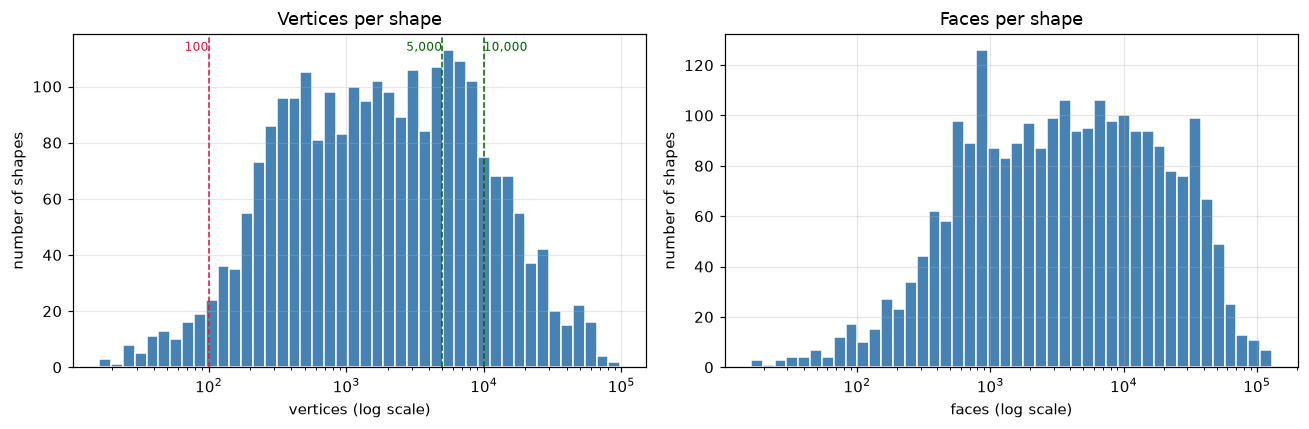

In [6]:
def hist_log(ax, s, label):
    bins = np.logspace(np.log10(s.min()), np.log10(s.max()), 45)
    ax.hist(s, bins=bins, color="steelblue", edgecolor="white")
    ax.set_xscale("log"); ax.set_xlabel(label + " (log scale)"); ax.set_ylabel("number of shapes")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
hist_log(axes[0], stats["n_vertices"], "vertices")
for x, c, t, ha in [(100, "crimson", "100", "right"), (LO, "darkgreen", "5,000", "right"), (HI, "darkgreen", "10,000", "left")]:
    axes[0].axvline(x, color=c, ls="--", lw=1); axes[0].text(x, axes[0].get_ylim()[1] * .95, t, color=c, fontsize=8, ha=ha)
axes[0].set_title("Vertices per shape")
hist_log(axes[1], stats["n_faces"], "faces")
axes[1].set_title("Faces per shape")
plt.tight_layout(); plt.savefig(FIG / "hist_vertices_faces.png", dpi=150); plt.show()

**Figure 2.1.** Histograms of the number of vertices (left) and faces (right) per shape for all 2,483 shapes, with logarithmic
horizontal axes. The dashed lines mark 100 vertices (red) and the target range of 5,000 to 10,000 vertices (green).

Both distributions are strongly right-skewed. The median number of vertices is 1,826, while the mean is 5,610, and the
counts range from 16 to 98,256. The assignment mentions shapes with hundreds of thousands of vertices; no shape in this
database comes close, since the largest has 98,256 vertices and 0 shapes have more than 100,000. Most shapes are
coarser than the target range used in Section 2.3: 1,733 shapes (69.8 %) have fewer than 5,000 vertices, only
361 (14.5 %) have between 5,000 and 10,000, and 389 (15.7 %) have more. 92 shapes have fewer
than 100 vertices.

The classes are not balanced either. Figure 2.2 shows that they contain between 15 and 143 shapes (mean
36), and that the typical resolution differs strongly between classes. Without a common resolution, a descriptor
could therefore partly measure how finely a class was modelled instead of the shape itself.

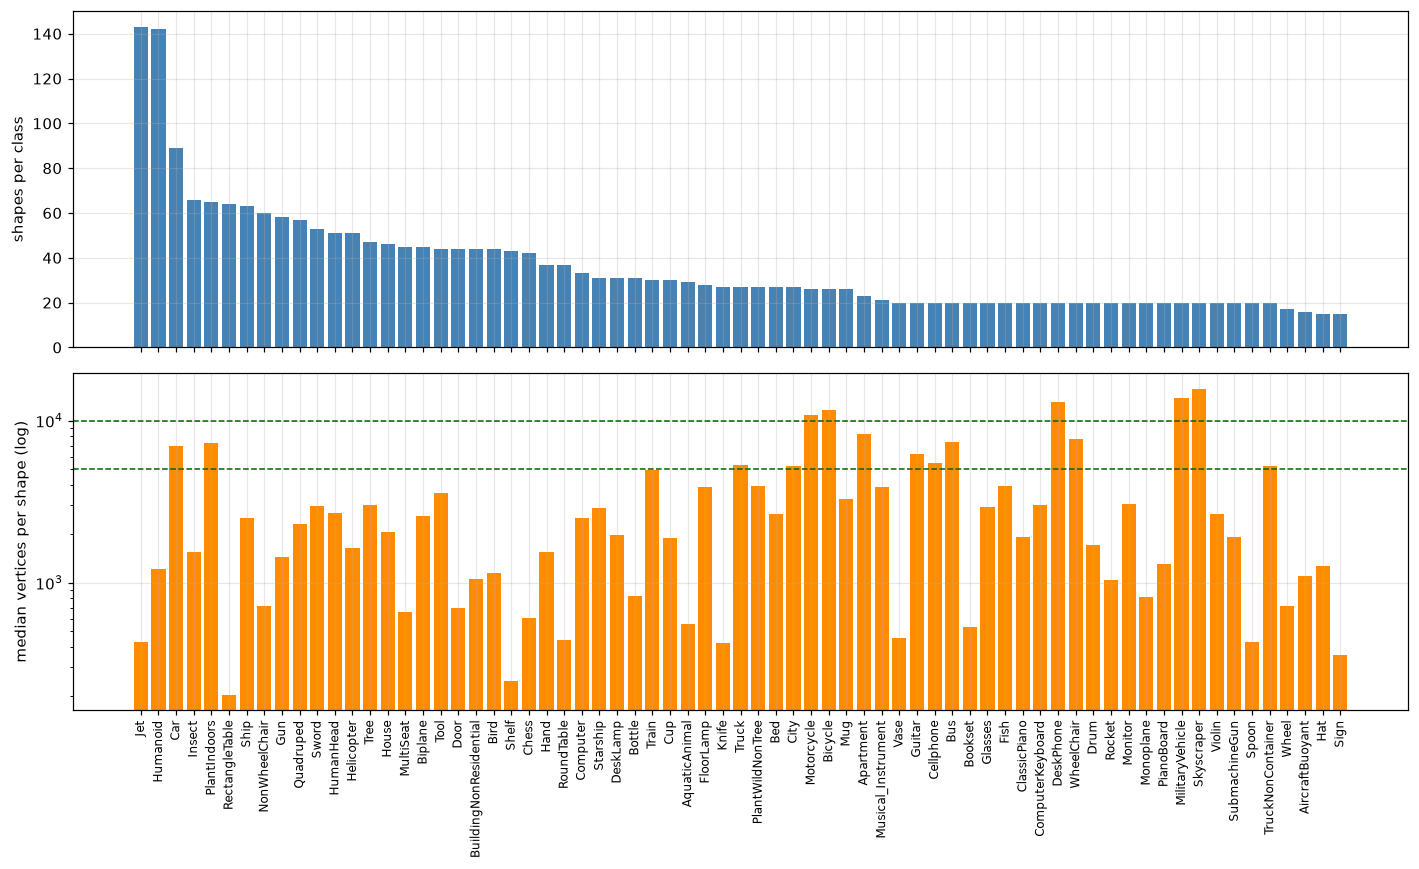

In [7]:
cls = stats.groupby("class").agg(n_shapes=("file", "size"), median_vertices=("n_vertices", "median"))
cls = cls.sort_values("n_shapes", ascending=False)
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].bar(cls.index, cls["n_shapes"], color="steelblue"); axes[0].set_ylabel("shapes per class")
axes[1].bar(cls.index, cls["median_vertices"], color="darkorange"); axes[1].set_yscale("log")
axes[1].set_ylabel("median vertices per shape (log)")
for y in (LO, HI):
    axes[1].axhline(y, color="darkgreen", ls="--", lw=1)
plt.xticks(rotation=90, fontsize=8); plt.tight_layout(); plt.savefig(FIG / "class_sizes_and_median_vertices.png", dpi=150); plt.show()

**Figure 2.2.** Number of shapes per class (top) and median number of vertices per class (bottom, logarithmic axis), with the
classes sorted by size. The dashed lines mark 5,000 and 10,000 vertices.

**Outliers.** Two definitions of an outlier are used. The statistical definition is Tukey's rule [7] applied to the vertex
counts, which flags shapes above the upper fence $Q_3+1.5\,\mathrm{IQR}$. The absolute definition is the one of the assignment:
fewer than 100 or more than 100,000 vertices. Figure 2.3 shows the three smallest shapes, the three shapes whose vertex
count is closest to the median, and the three largest shapes.

Tukey, raw counts : Q1=490, Q3=6,306, upper fence 15,032, lower fence -8,236; 247 shapes above the upper fence (9.9 %)
Tukey, log10 scale: fences [11, 291,637] -> 0 below, 0 above
absolute criteria : 92 shapes with < 100 vertices, 0 with > 100,000
classes of the high outliers: {'Car': 23, 'PlantIndoors': 21, 'Tree': 17, 'Bicycle': 13, 'Humanoid': 11}


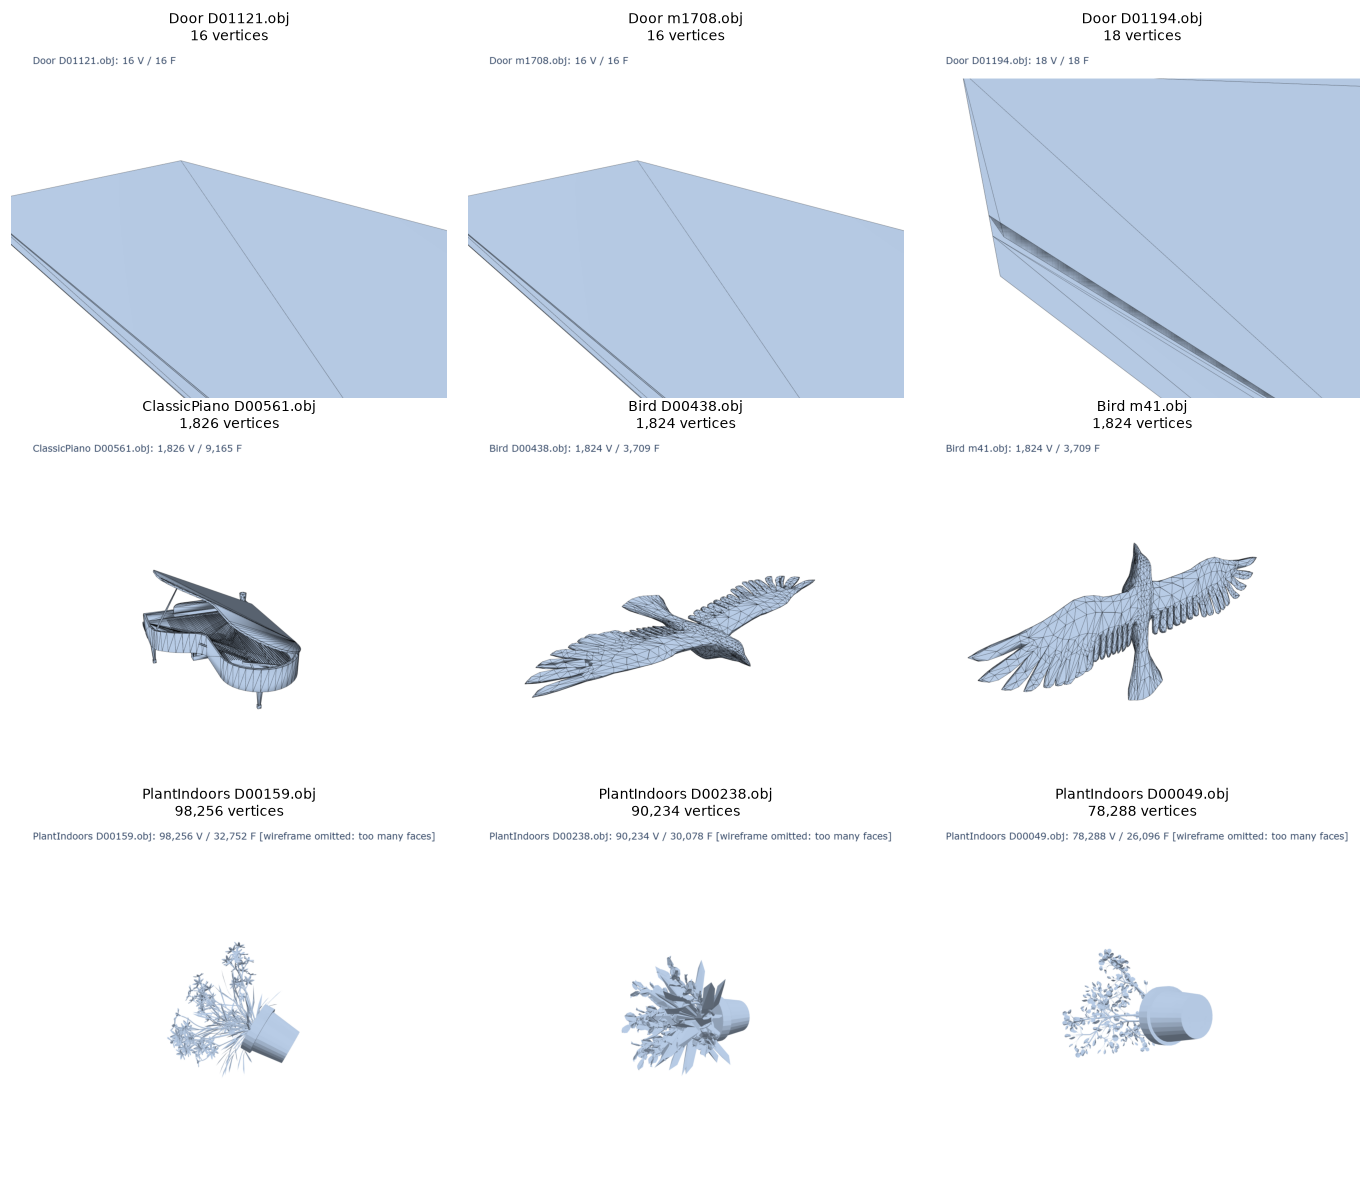

In [8]:
v = stats["n_vertices"]
q1, q3 = np.percentile(v, [25, 75]); fence = q3 + 1.5 * (q3 - q1)
low_l, high_l, (lf, hf) = mr_stats.tukey_outliers(v)
print(f"Tukey, raw counts : Q1={q1:,.0f}, Q3={q3:,.0f}, upper fence {fence:,.0f}, lower fence {q1 - 1.5 * (q3 - q1):,.0f}; "
      f"{(v > fence).sum()} shapes above the upper fence ({100 * (v > fence).mean():.1f} %)")
print(f"Tukey, log10 scale: fences [{lf:,.0f}, {hf:,.0f}] -> {low_l.sum()} below, {high_l.sum()} above")
print(f"absolute criteria : {(v < 100).sum()} shapes with < 100 vertices, {(v > 100000).sum()} with > 100,000")
print("classes of the high outliers:", stats[v > fence]["class"].value_counts().head(5).to_dict())

def pick(df):
    med = df["n_vertices"].median()
    return (list(df.nsmallest(3, "n_vertices").itertuples()) +
            list(df.iloc[(df["n_vertices"] - med).abs().to_numpy().argsort()[:3]].itertuples()) +
            list(df.nlargest(3, "n_vertices").itertuples()))

items = []
for r in pick(stats):
    V, F = mr_io.mesh_arrays(r.path)
    png = FIG / "outliers" / f"{r._1}_{r.file[:-4]}.png"
    mr_io.render_png(V, F, png, wireframe=True, title=f"{r._1} {r.file}: {r.n_vertices:,} V / {r.n_faces:,} F", width=600, height=480)
    items.append((png, f"{r._1} {r.file}\n{r.n_vertices:,} vertices"))
gallery(items, ncols=3, out=FIG / "gallery_outliers.png")

**Figure 2.3.** The three smallest shapes (top row, 16 to 18 vertices), the three shapes closest to the median vertex count
(middle row) and the three largest shapes (bottom row), with wireframe where the mesh is small enough. Meshes with more than
40,000 faces are decimated for display only, as stated in the panel titles.

Tukey's rule gives an upper fence of 15,032 vertices and flags 247 shapes (9.9 %), mostly from the classes
Car (23), PlantIndoors (21), Tree (17), Bicycle (13), Humanoid (11). The lower fence is negative, so no shape is a low outlier in the statistical sense; the low end is captured by
the absolute criterion, under which 92 shapes have fewer than 100 vertices. Applied to $\log_{10}N_V$, the same rule flags no
shape at all (fences at 11 and 291,637 vertices), which again shows how widely the resolution is spread.

**Quality of the raw meshes.** Besides the sampling resolution, the geometric quality of the raw meshes was measured.
Table 2.4 and Figure 2.4 show how many shapes have each kind of defect.

In [9]:
n = len(stats)
q = pd.Series({
    "inconsistent orientation (edge conflicts)": (~stats.winding_consistent).sum(),
    "has an inside-out closed component": (stats.n_inverted_components > 0).sum(),
    "has duplicate vertices": (stats.n_duplicate_vertices > 0).sum(),
    "has unused vertices": (stats.n_unused_vertices > 0).sum(),
    "has degenerate triangles": (stats.n_degenerate_faces > 0).sum(),
    "has non-manifold edges": (stats.n_nonmanifold_edges > 0).sum(),
    "not closed (boundary or non-manifold edges)": (~stats.closed).sum(),
})
tab = pd.DataFrame({"shapes": q, "percent": (100 * q / n).round(1)})
display(tab)

,shapes,percent
inconsistent orientation (edge conflicts),693,27.9
has an inside-out closed component,375,15.1
has duplicate vertices,698,28.1
has unused vertices,71,2.9
has degenerate triangles,454,18.3
has non-manifold edges,1350,54.4
not closed (boundary or non-manifold edges),2003,80.7


**Table 2.4.** Number and percentage of shapes with each kind of defect in the raw database.

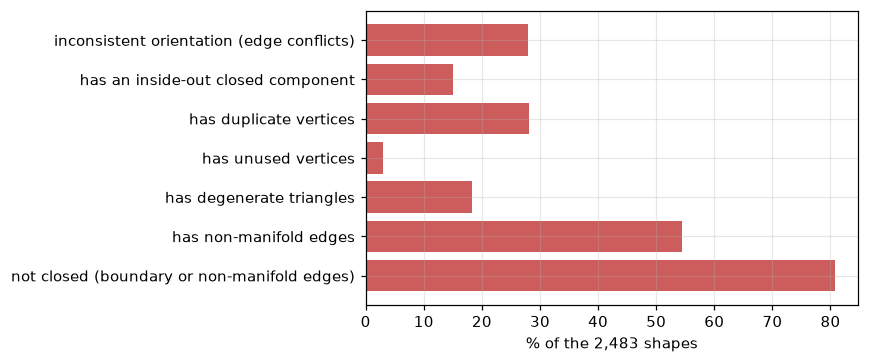

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(tab.index[::-1], tab["percent"][::-1], color="indianred"); ax.set_xlabel(f"% of the {n:,} shapes")
plt.tight_layout(); plt.savefig(FIG / "mesh_quality.png", dpi=150); plt.show()

**Figure 2.4.** Percentage of the shapes that have each kind of defect (same data as Table 2.4).

The raw meshes are far from clean. 693 shapes (28 %) contain orientation conflicts, 375 (15 %) contain an
inside-out closed component, 698 (28 %) contain duplicate vertices and 454 (18 %) contain degenerate
triangles. 81 % of the shapes are not closed, so only 480 shapes are closed surfaces. This justifies a
cleaning and orientation step before the resampling (Section 2.3), and it limits later steps: descriptors that need a volume are
well defined only for the minority of closed, consistently oriented shapes.

**Face orientation and the rendering of dense meshes.** To check that the orientation measurements describe what is visible, the
Hand shape (D01006, 15,855 triangles) was examined. Rendered with flat shading it shows irregular dark patches, although the
measurements report no orientation conflict, no inside-out component and a positive signed volume for this shape. As an
additional test, all faces were reversed. Figure 2.5 shows that the flat-shaded image is identical in this case, whereas smooth
shading shows the surface without patches.

Hand D01006: 15,855 triangles | conflicting edges: 0 | inside-out components: 0 | signed volume 0.0955


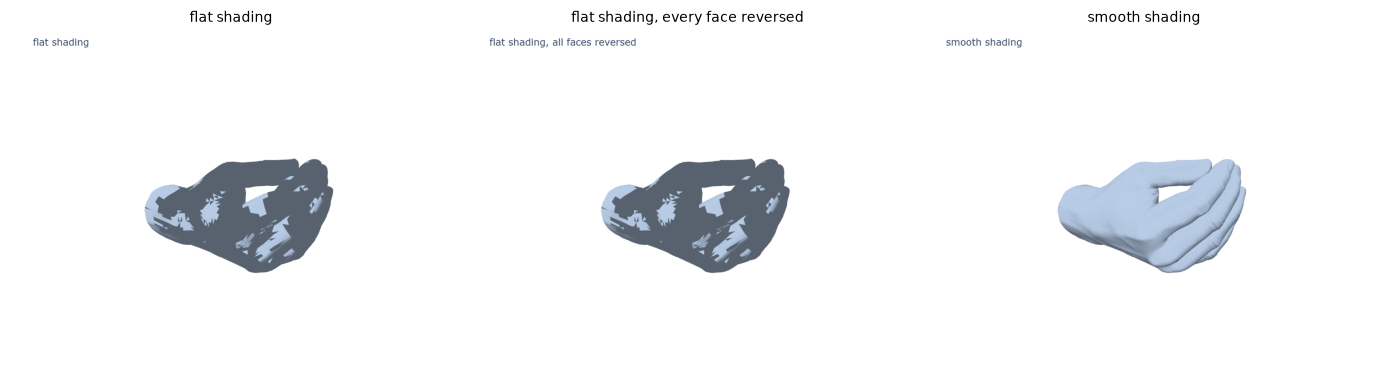

In [11]:
hand = DATA_DIR / "Hand" / "D01006.obj"
V, F = mr_io.mesh_arrays(hand)
r = mr_stats.analyze_obj(hand)
print(f"Hand D01006: {len(F):,} triangles | conflicting edges: {r['n_conflicting_edges']} | inside-out components: "
      f"{r['n_inverted_components']} | signed volume {r['signed_volume']:.4f}")
a = mr_io.render_png(V, F, FIG / "hand_flat.png", flatshading=True, title="flat shading", width=600, height=450)
b = mr_io.render_png(V, F[:, ::-1], FIG / "hand_flat_reversed.png", flatshading=True, title="flat shading, all faces reversed", width=600, height=450)
c_ = mr_io.render_png(V, F, FIG / "hand_smooth.png", flatshading=False, title="smooth shading", width=600, height=450)
gallery([(a, "flat shading"), (b, "flat shading, every face reversed"), (c_, "smooth shading")], ncols=3, out=FIG / "hand_shading_comparison.png")

**Figure 2.5.** The Hand shape (D01006) rendered with flat shading (left), with flat shading after reversing all faces (centre) and
with smooth shading (right).

The patches are therefore a property of the flat-shading renderer on dense meshes, where many triangles fall into one pixel, and
not of the mesh orientation. All renderings in this section use smooth shading.

## 2.3  Resampling

### 2.3.1  Aim and approach

The aim is to bring all shapes to a comparable sampling resolution without changing their geometry, and to make the meshes valid
enough for the later steps. The assignment asks to refine shapes with very few vertices, to simplify shapes with very many, and
to aim at about 5,000 to 10,000 vertices [1]. The course notes add that the target has to be a fixed value and not the average of
the database, that coarse shapes have to be refined and too fine shapes decimated, and that the sampling density should not vary
widely over the database [2].

Every shape passes through the pipeline
$$\text{raw OBJ}\;\rightarrow\;\text{clean}\;\rightarrow\;\text{orient}\;\rightarrow\;\text{resample}\;\rightarrow\;\text{orient}\;\rightarrow\;\text{OBJ}.$$
The course notes recommend remeshing as the last operation of the normalization pipeline [2]. Here the shapes are resampled first,
and the position and size normalization of Section 2.5 is applied to the resampled shapes. This is possible because translation and
scaling do not change the vertex count, and because the resampling does not depend on position or size: the edge length of the
refinement and the cost of the decimation scale with a uniform scaling and are invariant to a translation. Remeshing does change the
vertex set, so quantities that depend on it, such as a barycenter defined as the mean of the vertices, must be computed after the
resampling. The second orientation pass at the end of the pipeline is needed because decimation can re-introduce orientation
conflicts (Sections 2.3.8 and 2.3.9).

### 2.3.2  Target resolution and processing policy

The target is $V_{\text{target}}=7{,}500$ vertices, the middle of the range of 5,000 to 10,000 vertices given in the assignment. The
acceptance band is $[N_{lo},N_{hi}]=[5{,}000,10{,}000]$ and the tolerance is $\epsilon=10\,\%$, i.e. 6,750 to 8,250 vertices. Shapes
inside the band are only cleaned and re-oriented, shapes below the band are refined and shapes above it are decimated.

Three observations lead to this policy. First, the assignment gives 5,000 to 10,000 vertices as the target range [1]. Second, the
descriptors of the next step are defined on random vertices, so they are only comparable if shapes have a similar vertex density;
in the lecture, mesh resolution is listed among the properties that are uninteresting for retrieval and should be normalized away,
together with location, size and orientation [3]. Third, a policy that treats only the extreme shapes, with fewer than 100 or more
than 100,000 vertices, would leave resolutions between 100 and 98,000 vertices in the database, because no shape exceeds 100,000
vertices. Table 2.5 compares four policies by the number of shapes that each of them modifies.

In [12]:
v = stats["n_vertices"]
pol = pd.DataFrame([
    ("A: band [5,000, 10,000] (used)", (v < 5000).sum(), (v > 10000).sum()),
    ("B: refine < 100, decimate > 100,000", (v < 100).sum(), (v > 100000).sum()),
    ("C: band [1,000, 20,000]", (v < 1000).sum(), (v > 20000).sum()),
    ("D: refine < 100, decimate > 10,000", (v < 100).sum(), (v > 10000).sum()),
], columns=["policy", "shapes refined", "shapes decimated"])
pol["shapes modified"] = pol["shapes refined"] + pol["shapes decimated"]
pol["% of database"] = (100 * pol["shapes modified"] / len(v)).round(1)
display(pol)

,policy,shapes refined,shapes decimated,shapes modified,% of database
0,"A: band [5,000, 10,000] (used)",1733,389,2122,85.5
1,"B: refine < 100, decimate > 100,000",92,0,92,3.7
2,"C: band [1,000, 20,000]",928,159,1087,43.8
3,"D: refine < 100, decimate > 10,000",92,389,481,19.4


**Table 2.5.** Number of shapes that would be refined and decimated under four processing policies, counted on the raw vertex numbers.

The policy of the band (A) modifies the largest number of shapes. Counted on the cleaned vertex numbers, it refines 1,754 shapes,
decimates 362 and keeps 367, i.e. it modifies 85.2 % of the database. This is acceptable because refinement does not
move the surface (Section 2.3.8) and the deviation caused by decimation is measured for every shape.

### 2.3.3  Cleaning

The raw meshes are cleaned in four steps. First, vertices with identical coordinates are merged, $v_i\sim v_k\iff v_i=v_k$; decimation
contracts edges between shared vertices, so it cannot work across unmerged seams. Second, polygons are fan-triangulated, which has
no effect on this database. Third, degenerate triangles (Section 2.1) and exact duplicates of faces are removed. Fourth, unused
vertices are removed. The raw counts are reported before cleaning (Sections 2.1 and 2.2), while the resampling target refers to the
cleaned vertex count. Removing duplicate and degenerate faces turns non-manifold edges into manifold ones, so more orientation
conflicts are visible after cleaning (Table 2.16) than in the statistics of the raw faces (Table 2.4).

### 2.3.4  Orientation

Two faces $f$ and $g$ that share a manifold edge are consistent if they list the edge in opposite directions. Let $s(f,g)=1$ if both
list it in the same direction. For every connected component a seed face is chosen, and the flip state is propagated over the
face-adjacency graph, depth-first:
$$\text{flip}(\text{seed})=0,\qquad \text{flip}(g)=\text{flip}(f)\oplus s(f,g).$$
Faces with $\text{flip}=1$ are reversed; only edges that are shared by exactly two faces are followed. Because the orientation of the
seed is arbitrary, a second, global step examines each component: if at most 1 % of its faces touch a boundary or non-manifold edge
(the component is nearly closed) and its signed volume is negative, the component is turned inside-out. For clearly open surfaces
the sign of the volume has no meaning, so they are left unchanged. If the constraints contradict each other, as for non-orientable
or folded geometry, conflicts remain; they are counted per shape and stored as `orientation_ok`.

### 2.3.5  Refinement of shapes with $N_V<N_{lo}$

The refinement is adaptive and based on edge length. In one pass, every edge that is longer than a length $L$ is split at its
midpoint. The midpoint is shared by the two faces of the edge, so the mesh stays watertight. A triangle with $k=0,1,2,3$ split edges
is replaced by $1,2,3,4$ triangles that keep the vertex order of the original and therefore its orientation. The pass is repeated
until no edge is longer than $L$. A surface of area $A$ that is covered by equilateral triangles of edge $L$ has
$N_F\approx 4A/(\sqrt3L^2)$ faces and about $N_F/2$ vertices, so the start value of $L$ for a target of $V_{\text{target}}$ vertices is
$$L_0=1.4\sqrt{\frac{4A}{\sqrt3\cdot 2V_{\text{target}}}},$$
where the factor 1.4 accounts for the fact that splitting leaves edges between $L/2$ and $L$. Because $N_V\propto L^{-2}$, the length is
corrected after each attempt by $L\leftarrow L\sqrt{N_V/V_{\text{target}}}$, and the refinement is restarted from the original mesh, at
most eight times. Of all attempts, the result inside the band that is closest to $V_{\text{target}}$ is kept. Since only edges that are
too long are split, large triangles are refined and small triangles are left alone, which makes the triangle sizes more uniform.

As a baseline, uniform midpoint subdivision was also implemented. Every triangle is split into four ($N_F\to4N_F$,
$N_V\to N_V+|E|$) until $N_V\ge V_{\text{target}}$, and the result is decimated to the target. The two methods are compared in
Section 2.3.8.

### 2.3.6  Decimation of shapes with $N_V>N_{hi}$

Quadric error metric decimation [4] assigns to every vertex the quadric $Q_v=\sum_p \mathbf{p}\mathbf{p}^{T}$, summed over the planes
$\mathbf{p}=(a,b,c,d)$, $a^2+b^2+c^2=1$, of its adjacent faces. It repeatedly contracts the edge $(v_1,v_2)$ with the smallest cost
$\bar v^{T}(Q_1+Q_2)\bar v$, where $\bar v$ is the new position in homogeneous coordinates, until a requested number of triangles is
reached. The Open3D implementation [5] is driven by a triangle count. The first guess is $F_t=V_{\text{target}}/\rho$ with
$\rho=N_V/N_F\in[0.3,0.7]$ (about $\tfrac12$ for a closed surface), which is corrected by $F_t\leftarrow F_t\,V_{\text{target}}/V_{\text{out}}$ until
$|V_{\text{out}}-V_{\text{target}}|\le\epsilon V_{\text{target}}$, at most five times.

Quadric decimation optimizes the fidelity of the shape and not the uniformity of the triangles, and it fails on some shapes
(Section 2.3.10). Every decimation result is therefore checked. It is accepted if it lies inside the band and its Hausdorff
deviation from the input surface is at most $\delta_{\max}=5\,\%$ of the bounding-box diagonal. Otherwise two alternatives are tried in
turn and the best result, inside the band and with the smallest deviation, is kept. The first alternative is quadric decimation
with a boundary weight of 100, which penalizes moving the boundaries of open surfaces. The second is vertex clustering [6]: space
is divided into voxels of size $s$, all vertices in a voxel are replaced by their mean, and faces that collapse are removed. The
vertex count does not increase with $s$, so $s$ is found by bisection (accepting $|V_{\text{out}}-V_{\text{target}}|\le5\,\%$). Every part
of the mesh moves by at most about one voxel, so thin or loose parts cannot disappear.

### 2.3.7  Examples

Figure 2.6 and Table 2.6 show a refined shape (Bird), a decimated shape (House D00001) and an inside-out shape (Chess)
before and after the processing.

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


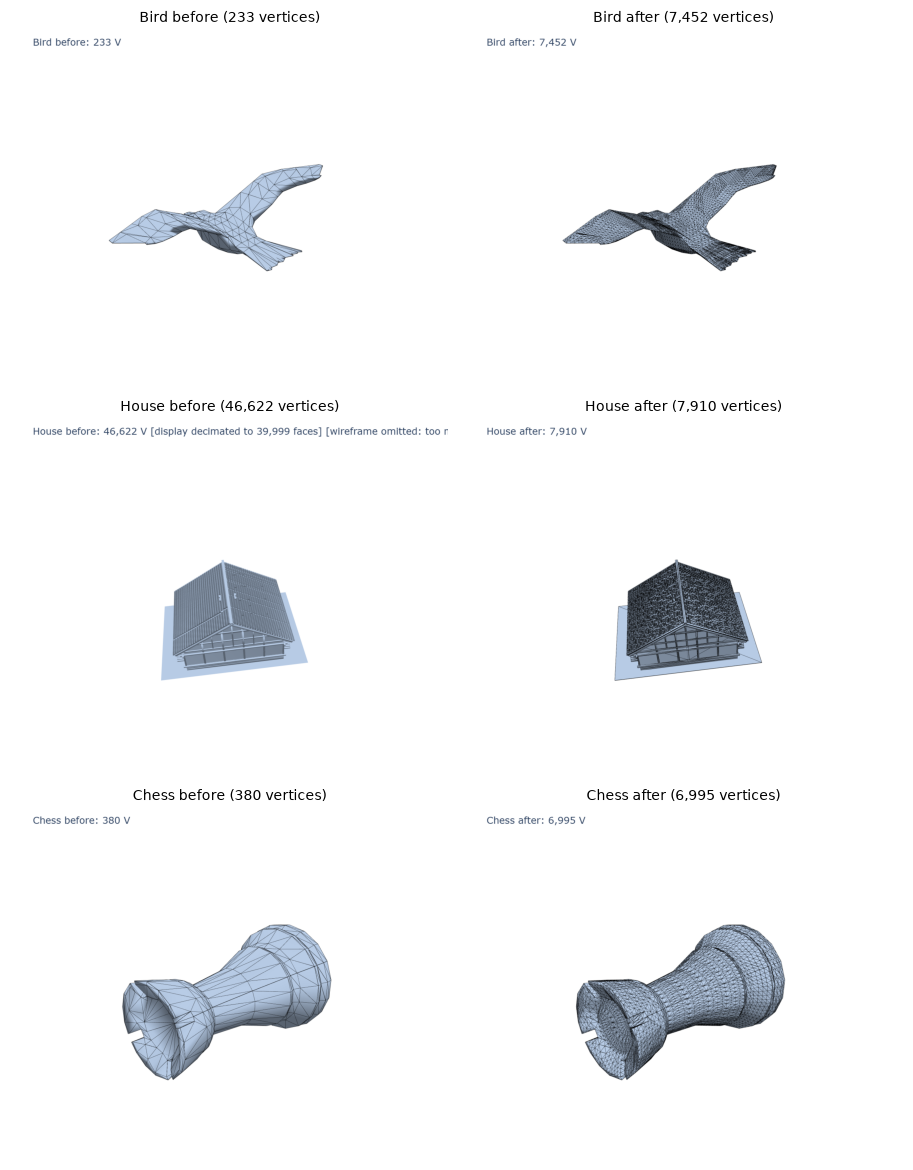

In [13]:
demo_dir = PROCESSED / "step2_demo"
rows, items = [], []
for c, f in [("Bird", "D00089"), ("House", "D00001"), ("Chess", "D01017")]:
    src = DATA_DIR / c / f"{f}.obj"
    dst = demo_dir / c / f"{f}.obj"
    rec = mr_resample.process_file((str(src), str(dst), mr_resample.V_TARGET, mr_resample.BAND, "adaptive"))
    rows.append(rec)
    Vb, Fb = mr_io.mesh_arrays(src)
    Va, Fa = mr_io.mesh_arrays(dst)
    pb = mr_io.render_png(Vb, Fb, FIG / "demo" / f"{c}_before.png", wireframe=True, title=f"{c} before: {len(Vb):,} V", width=600, height=480)
    pa = mr_io.render_png(Va, Fa, FIG / "demo" / f"{c}_after.png", wireframe=True, title=f"{c} after: {len(Va):,} V", width=600, height=480)
    items += [(pb, f"{c} before ({len(Vb):,} vertices)"), (pa, f"{c} after ({len(Va):,} vertices)")]
demo_log = pd.DataFrame(rows)
gallery(items, ncols=2, out=FIG / "demo_before_after.png")

**Figure 2.6.** Bird (D00089), House (D00001) and Chess (D01017) before (left) and after (right) the processing. Wireframes are
drawn when the mesh has at most 25,000 faces.

In [14]:
display(demo_log[["class", "v_raw", "v_clean", "merged_duplicates", "orient_inverted_components", "action", "subdiv_iters", "decim_iters",
                  "decim_method", "v_out", "f_out", "area_cv_before", "area_cv_after", "chamfer_rel", "hausdorff_rel", "status"]].round(4))

,class,v_raw,v_clean,merged_duplicates,orient_inverted_components,action,subdiv_iters,decim_iters,decim_method,v_out,f_out,area_cv_before,area_cv_after,chamfer_rel,hausdorff_rel,status
0,Bird,233,233,0,0,refined,3,0,,7452,14900,0.6814,0.5626,0.0000,0.0000,ok
1,House,46622,46252,370,4,decimated,0,3,quadric,7910,8843,30.4250,12.8593,0.0002,0.0215,ok
2,Chess,380,380,0,1,refined,2,0,,6995,13986,1.4093,0.5776,0.0000,0.0000,ok


**Table 2.6.** Processing log of the three example shapes: vertex counts before and after cleaning, merged duplicates, turned
inside-out components, action, number of refinement attempts and decimation iterations, decimation method, final vertex and
face counts, triangle-size variation (CV) before and after, and surface deviation.

Bird has 233 vertices and is refined to 7,452 vertices; 3 attempts were needed to find the edge length and no
decimation was necessary. The surface does not move, and the variation of the triangle areas decreases from 0.68 to
0.56. House has 46,622 raw vertices, 46,252 after merging 370 duplicates, and 7,910 after decimation
(method: quadric). Its surface deviates by at most 2.2 % of the diagonal, and 4 inside-out components were turned.
The large variation of its triangle areas (30.4 before, 12.9 after) comes from huge flat triangles of the ground
plane next to small roof tiles, which decimation cannot equalize. Chess is refined from 380 to 6,995 vertices, and its
inward-facing component, which has a negative signed volume, is turned outward.

### 2.3.8  Evaluation on a reduced database

As required by the assignment, the pipeline was first developed and evaluated on a reduced, balanced database. It contains three
random shapes of each of the 69 classes (seed 42), i.e. 207 shapes, plus the five smallest and the five largest shapes
of the database as stress tests (10 shapes), 217 shapes in total. The selection is stored in
`report/data/step2/reduced_database.csv`. Table 2.7 and Figure 2.7 show the effect of the processing on the vertex counts.

In [15]:
reduced = pd.read_csv(DATA_OUT / "reduced_database.csv")
log = mr_resample.run_pipeline(reduced, PROCESSED / "step2_reduced", workers=8,
                               cache_csv=DATA_OUT / "resample_log_reduced.csv")      # saved result is re-used
print(f"reduced database: {len(reduced)} shapes ({reduced.group.value_counts().to_dict()}), {reduced['class'].nunique()} classes; "
      f"status {log.status.value_counts().to_dict()}, actions {log.action.value_counts().to_dict()}")
display(pd.DataFrame({"raw vertices": log["v_raw"].describe(), "after cleaning": log["v_clean"].describe(),
                      "after resampling": log["v_out"].describe()}).round(0))

reduced database: 217 shapes ({'balanced': 207, 'stress': 10}), 69 classes; status {'ok': 217}, actions {'refined': 137, 'kept': 43, 'decimated': 37}


,raw vertices,after cleaning,after resampling
count,217.0,217.0,217.0
mean,7586.0,5629.0,7528.0
std,14552.0,8320.0,764.0
min,16.0,16.0,5202.0
25%,538.0,524.0,7138.0
50%,2288.0,2252.0,7606.0
75%,7627.0,7435.0,8029.0
max,98256.0,73440.0,9738.0


**Table 2.7.** Statistics of the vertex counts of the reduced database as stored in the files, after cleaning and after resampling.

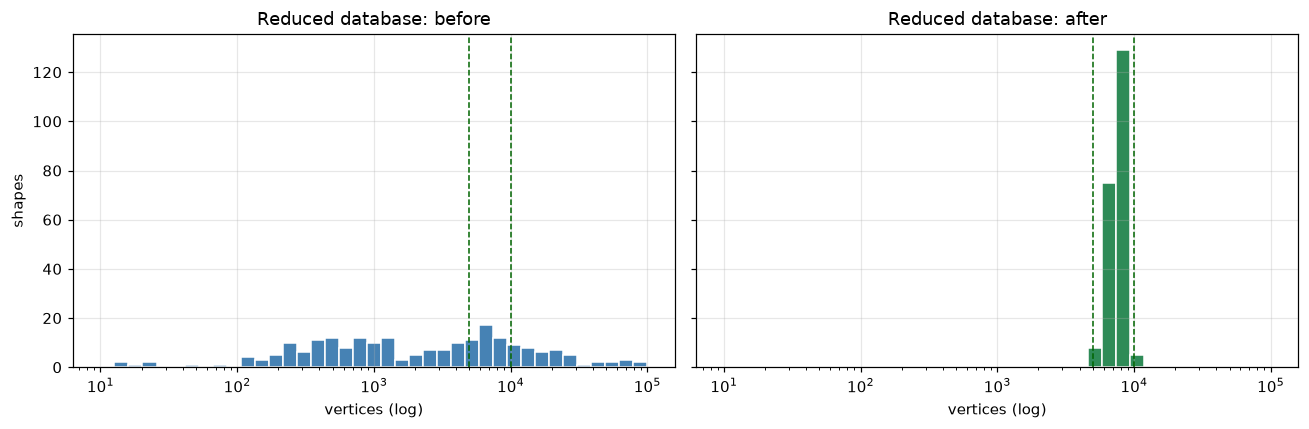

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
bins = np.logspace(1, 5, 40)
axes[0].hist(log["v_raw"], bins=bins, color="steelblue", edgecolor="white"); axes[0].set_xscale("log")
axes[0].set_title("Reduced database: before"); axes[0].set_xlabel("vertices (log)"); axes[0].set_ylabel("shapes")
axes[1].hist(log["v_out"], bins=bins, color="seagreen", edgecolor="white"); axes[1].set_xscale("log")
axes[1].set_title("Reduced database: after"); axes[1].set_xlabel("vertices (log)")
for ax in axes:
    for x in (LO, HI):
        ax.axvline(x, color="darkgreen", ls="--", lw=1)
plt.tight_layout(); plt.savefig(FIG / "hist_reduced_before_after.png", dpi=150); plt.show()

**Figure 2.7.** Histograms of the number of vertices of the reduced database before (left) and after (right) the processing. The
dashed lines mark 5,000 and 10,000 vertices.

All 217 shapes were processed without failure: 137 were refined, 37 decimated and 43 kept. After the processing every
shape lies inside the band, with a minimum of 5,202 and a maximum of 9,738 vertices. The mean is 7,528 for a target of 7,500,
and the standard deviation is 764 (14,552 before). The share of shapes inside the band rises from 19.8 % to 100.0 %, and the
mean distance to the target falls from 6,276 to 563 vertices. The average resolution is therefore close to the target value,
and its spread is small.

The two refinement methods are compared in Table 2.8. The uniform baseline makes the triangle sizes less uniform (median CV
2.31 before, 6.12 after), because decimating the oversampled mesh removes the cheapest edges first, which lie in flat regions, and
thereby re-creates large triangles next to small ones. Its largest surface deviation is 2.6 % of the diagonal. Adaptive refinement
lowers the median CV to 0.88 and has a largest deviation of 0.08 %; the median chamfer distance of 3.8e-8 is numerical
rounding, since refinement does not move the surface. Both methods need the same time, so adaptive refinement is used.

In [17]:
U = pd.read_csv(DATA_OUT / "resample_log_reduced_uniform.csv")
rows = []
for name, L in [("uniform midpoint subdivision + decimation (baseline)", U), ("adaptive edge-length refinement (used)", log)]:
    r = L[L.action == "refined"]
    rows.append({"refinement method": name, "refined shapes": len(r),
                 "median area CV before": r.area_cv_before.median(), "median area CV after": r.area_cv_after.median(),
                 "max surface deviation (Hausdorff)": r.hausdorff_rel.max(), "mean seconds/shape": r.seconds.mean()})
display(pd.DataFrame(rows).round(3).set_index("refinement method").T)

refinement method,uniform midpoint subdivision + decimation (baseline),adaptive edge-length refinement (used)
refined shapes,137.000,137.000
median area CV before,2.311,2.311
median area CV after,6.117,0.882
max surface deviation (Hausdorff),0.026,0.001
mean seconds/shape,1.145,1.018


**Table 2.8.** Comparison of the two refinement methods on the refined shapes of the reduced database: median coefficient of variation
of the triangle areas before and after, largest surface deviation relative to the diagonal, and run time.

In [18]:
display(log.groupby("action").agg(shapes=("file", "size"), cv_before=("area_cv_before", "median"), cv_after=("area_cv_after", "median"),
                                  chamfer_median=("chamfer_rel", "median"), chamfer_p95=("chamfer_rel", lambda s: s.quantile(.95)),
                                  hausdorff_p95=("hausdorff_rel", lambda s: s.quantile(.95)), hausdorff_max=("hausdorff_rel", "max")))

,shapes,cv_before,cv_after,chamfer_median,chamfer_p95,hausdorff_p95,hausdorff_max
action,,,,,,,
decimated,37,4.811566,3.590448,1.161521e-05,3.765407e-04,0.025716,0.045275
kept,43,3.486612,3.486612,0.000000e+00,0.000000e+00,0.000000,0.000000
refined,137,2.310736,0.881738,3.754706e-08,4.967578e-07,0.000353,0.000792


**Table 2.9.** Triangle-size variation (median CV) and surface deviation (chamfer and Hausdorff, relative to the diagonal) by
processing action on the reduced database.

In [19]:
display(pd.DataFrame({
    "stage": ["after cleaning", "after 1st orientation pass", "after resampling", "after final orientation pass"],
    "shapes with conflicts": [(log.orient_conflicts_before > 0).sum(), (log.orient_conflicts_after > 0).sum(),
                              (log.conflicts_after_resample > 0).sum(), (log.conflicts_final > 0).sum()],
    "conflicting edges": [log.orient_conflicts_before.sum(), log.orient_conflicts_after.sum(),
                          log.conflicts_after_resample.sum(), log.conflicts_final.sum()],
}))

,stage,shapes with conflicts,conflicting edges
0,after cleaning,94,49836
1,after 1st orientation pass,10,584
2,after resampling,20,1031
3,after final orientation pass,11,551


**Table 2.10.** Number of shapes with orientation conflicts and number of conflicting edges after each stage of the pipeline, reduced
database.

Table 2.9 shows that refinement keeps the surface in place and decimation moves it only little. Table 2.10 shows the effect on
the orientation. The first orientation pass reduces the number of shapes with conflicts from 94 to 10. Decimation then
re-introduces conflicts in 20 shapes, and the final pass brings the number down to 11. In total, 206 of the 217 shapes
end consistently oriented.

### 2.3.9  Evaluation on the complete database

After the reduced database, the pipeline was applied to all 2,483 shapes, using 8 worker processes. This took 397 s of
wall-clock time and 3,119 s of CPU time; the slowest shape needed 13.4 s. The resampled meshes are stored in
`processed/step2_full/` and the log of every shape in `report/data/step2/resample_log_full.csv`. Table 2.11 and Figure 2.8
show the effect on the vertex counts.

In [20]:
full = mr_resample.run_pipeline(stats, PROCESSED / "step2_full", workers=8,
                                cache_csv=DATA_OUT / "resample_log_full.csv")        # saved result is re-used
print(f"{len(full)} shapes | status {full.status.value_counts().to_dict()} | actions {full.action.value_counts().to_dict()}")
display(pd.DataFrame({"raw vertices": full["v_raw"].describe(), "after cleaning": full["v_clean"].describe(),
                      "after resampling": full["v_out"].describe()}).round(0))

2483 shapes | status {'ok': 2483} | actions {'refined': 1754, 'kept': 367, 'decimated': 362}


,raw vertices,after cleaning,after resampling
count,2483.0,2483.0,2483.0
mean,5610.0,5019.0,7506.0
std,9851.0,8144.0,779.0
min,16.0,16.0,5010.0
25%,490.0,480.0,7200.0
50%,1826.0,1724.0,7591.0
75%,6306.0,6072.0,7960.0
max,98256.0,73440.0,9961.0


**Table 2.11.** Statistics of the vertex counts of all shapes as stored in the files, after cleaning and after resampling.

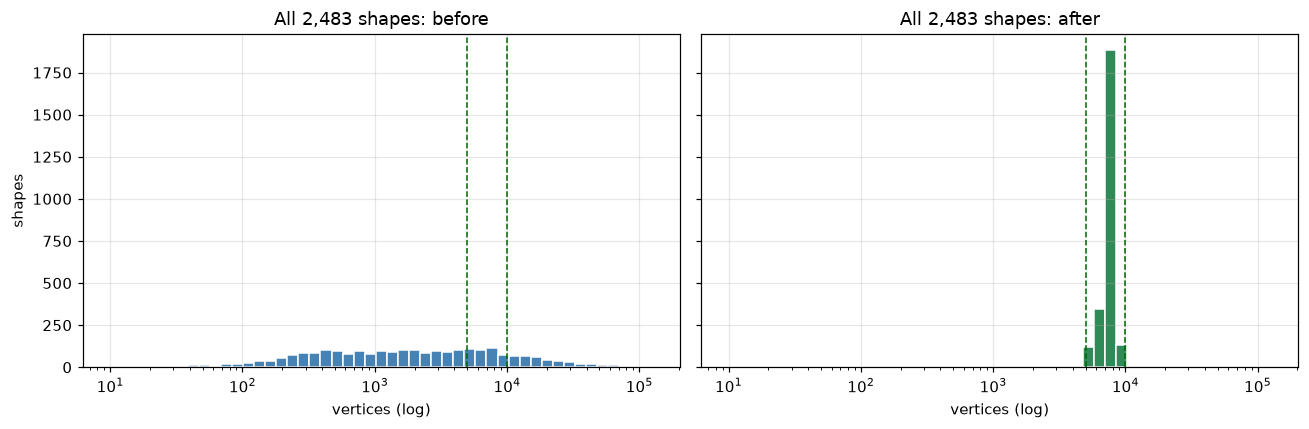

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
bins = np.logspace(1, 5.1, 50)
axes[0].hist(full["v_raw"], bins=bins, color="steelblue", edgecolor="white"); axes[0].set_title(f"All {len(full):,} shapes: before")
axes[1].hist(full["v_out"], bins=bins, color="seagreen", edgecolor="white"); axes[1].set_title(f"All {len(full):,} shapes: after")
for ax in axes:
    ax.set_xscale("log"); ax.set_xlabel("vertices (log)")
    for x in (LO, HI):
        ax.axvline(x, color="darkgreen", ls="--", lw=1)
axes[0].set_ylabel("shapes")
plt.tight_layout(); plt.savefig(FIG / "hist_full_before_after.png", dpi=150); plt.show()

**Figure 2.8.** Histograms of the number of vertices of all 2,483 shapes before (left) and after (right) the processing. The dashed
lines mark 5,000 and 10,000 vertices.

2,483 of the 2,483 shapes (100.00 %) end inside the band, 0 end outside it and 0 failed. The mean is 7,506
vertices with a standard deviation of 779, and the mean distance to the target falls from 6,453 to 550
vertices. 1,754 shapes were refined, 362 were decimated and 367 were kept. No shape was removed, so the class sizes are
unchanged (15 to 143 shapes per class).

Decimation was applied to 376 shapes, namely the 362 decimated shapes and refined shapes that ended above the band.
Table 2.12 shows which method produced the accepted result.

In [22]:
display(full.decim_method.fillna("").replace("", "no decimation").value_counts().rename("shapes").to_frame())

,shapes
decim_method,
no decimation,2107
quadric,368
vertex_clustering,7
quadric_bw100,1


**Table 2.12.** Method that produced the accepted result for each shape of the complete database.

In [23]:
display(full.groupby("action").agg(shapes=("file", "size"), cv_before=("area_cv_before", "median"), cv_after=("area_cv_after", "median"),
                                   chamfer_median=("chamfer_rel", "median"), chamfer_p95=("chamfer_rel", lambda s: s.quantile(.95)),
                                   hausdorff_p95=("hausdorff_rel", lambda s: s.quantile(.95)), hausdorff_max=("hausdorff_rel", "max")))

,shapes,cv_before,cv_after,chamfer_median,chamfer_p95,hausdorff_p95,hausdorff_max
action,,,,,,,
decimated,362,4.299973,3.432328,1.259053e-05,4.279030e-04,0.022632,0.046776
kept,367,3.720751,3.720751,0.000000e+00,0.000000e+00,0.000000,0.000000
refined,1754,2.094700,0.862486,2.478570e-08,9.619925e-07,0.000399,0.000889


**Table 2.13.** Triangle-size variation (median CV) and surface deviation (chamfer and Hausdorff, relative to the diagonal) by
processing action on the complete database.

In [24]:
display(full.nlargest(5, "hausdorff_rel")[["class", "file", "v_clean", "v_out", "decim_method", "hausdorff_rel", "chamfer_rel"]].round(3))

,class,file,v_clean,v_out,decim_method,hausdorff_rel,chamfer_rel
2322,Tree,D00533.obj,31668,7382,quadric,0.047,0.003
1448,MilitaryVehicle,D00173.obj,17299,7663,quadric,0.045,0.000
1705,PlantIndoors,D00080.obj,64126,7397,vertex_clustering,0.045,0.002
2329,Tree,D00834.obj,52078,7301,quadric,0.043,0.003
2099,Skyscraper,D00126.obj,25712,7313,quadric,0.042,0.003


**Table 2.14.** The five largest surface deviations of the complete database.

Refinement does not move the surface: the median chamfer distance is 2.5e-8, and the Hausdorff deviation is at most 0.09 %
of the diagonal. It also makes the triangle sizes more uniform (median CV 2.09 before, 0.86 after). Decimation
moves the surface little: the median chamfer distance is 1.3e-5, and the Hausdorff deviation is below 2.26 % for 95 %
of the shapes and at most 4.68 % (Table 2.14); 0 of the 362 decimated shapes deviate by more than 5 %. Decimation
improves the uniformity only moderately (median CV 4.30 before, 3.43 after), and shapes that were already inside
the band keep their triangle sizes (median CV 3.72).

In [25]:
clean = pd.Series({
    "duplicate vertices merged": (full.merged_duplicates > 0).sum(),
    "unused vertices removed": (full.unused_removed > 0).sum(),
    "degenerate triangles removed": (full.degenerate_removed > 0).sum(),
    "duplicate faces removed": (full.duplicate_faces_removed > 0).sum(),
    "inside-out component turned": (full.orient_inverted_components > 0).sum(),
})
display(pd.DataFrame({"shapes": clean, "percent": (100 * clean / len(full)).round(1)}))

,shapes,percent
duplicate vertices merged,698,28.1
unused vertices removed,71,2.9
degenerate triangles removed,454,18.3
duplicate faces removed,917,36.9
inside-out component turned,449,18.1


**Table 2.15.** Number and percentage of shapes of the complete database in which each cleaning operation was applied.

In [26]:
display(pd.DataFrame({
    "stage": ["after cleaning", "after 1st orientation pass", "after resampling", "after final orientation pass"],
    "shapes with conflicts": [(full.orient_conflicts_before > 0).sum(), (full.orient_conflicts_after > 0).sum(),
                              (full.conflicts_after_resample > 0).sum(), (full.conflicts_final > 0).sum()],
    "conflicting edges": [full.orient_conflicts_before.sum(), full.orient_conflicts_after.sum(),
                          full.conflicts_after_resample.sum(), full.conflicts_final.sum()],
}))
print(f"orientation_ok: {full.orientation_ok.sum()} / {len(full)} ({100 * full.orientation_ok.mean():.1f} %); vertices merged in total: {full.merged_duplicates.sum():,}")

,stage,shapes with conflicts,conflicting edges
0,after cleaning,882,285868
1,after 1st orientation pass,66,2264
2,after resampling,111,3614
3,after final orientation pass,63,2179


orientation_ok: 2420 / 2483 (97.5 %); vertices merged in total: 1,438,321


**Table 2.16.** Number of shapes with orientation conflicts and number of conflicting edges after each stage of the pipeline, complete
database.

Cleaning was necessary for a large part of the database (Table 2.15). 698 shapes contained duplicate vertices, with 1,438,321
vertices merged in total, 917 shapes contained duplicate faces, 454 contained degenerate triangles and 71 contained
unused vertices. 449 shapes contained an inside-out component. As Table 2.16 shows, 882 shapes have orientation conflicts after
cleaning, 66 after the first orientation pass, 111 after the resampling and 63 after the final pass, with 2,179 conflicting
edges remaining. 2,420 shapes (97.5 %) are consistently oriented. The others contain folded or non-orientable parts; they are
flagged with `orientation_ok = False` and not removed.

### 2.3.10  Shapes for which standard decimation fails

With quadric decimation alone, six of the 2,483 shapes were problematic. Four ended outside the band (House D00286 and D00901,
PlantIndoors D00080 and Tree D00765), and four Houses (D00286, D00901, D00574 and D00903) deviated by 13 to 19 % of their diagonal
from the original surface; two shapes belong to both groups. Table 2.17 lists the six shapes, and Figure 2.9 and Figure 2.10 show
the cleaned originals, the result of quadric decimation alone and the final result.

The four Houses are scenes of more than 9,800 loose parts each (roof tiles, wall panels, a ground plane) with thousands of
non-manifold edges. For D00286, D00901 and D00574, quadric decimation removes the walls and the ground plane and leaves only the roof
tiles; for D00903 it removes the ground plane. PlantIndoors and Tree are collections of thousands of small open surfaces (leaves), for
which the triangle target cannot be steered into the band. The increased boundary weight brings both into the band and lowers the
deviation, and vertex clustering handles all six shapes. These findings led to the checked decimation with alternatives described in
Section 2.3.6.

In [27]:
EXC = [("House", "D00286"), ("House", "D00901"), ("House", "D00574"), ("House", "D00903"), ("PlantIndoors", "D00080"), ("Tree", "D00765")]
rows, items = [], []
for c, f in EXC:
    src = DATA_DIR / c / f"{f}.obj"
    Vc, Fc, _ = mr_resample.clean_mesh(*mr_io.read_obj_raw(src))
    Fc, _ = mr_resample.fix_orientation(Vc, Fc)
    Vq, Fq, _ = mr_resample.decimate_to_vertices(Vc, Fc, VT)                  # standard quadric decimation only
    fq = mr_resample.fidelity(Vc, Fc, Vq, Fq)
    fin = full[(full["class"] == c) & (full.file == f + ".obj")].iloc[0]       # final result of the pipeline
    Vf, Ff = mr_io.mesh_arrays(PROCESSED / "step2_full" / c / f"{f}.obj")
    rows.append({"shape": f"{c} {f}", "cleaned vertices": len(Vc),
                 "quadric only: vertices": len(Vq), "quadric only: deviation %": round(100 * fq["hausdorff_rel"], 1),
                 "final: method": fin.decim_method, "final: vertices": int(fin.v_out), "final: deviation %": round(100 * fin.hausdorff_rel, 1)})
    names = [f"{c} {f}\ncleaned original ({len(Vc):,} V)", f"quadric only ({len(Vq):,} V)", f"final: {fin.decim_method} ({len(Vf):,} V)"]
    for tag, (VV, FF) in zip(["orig", "quadric", "final"], [(Vc, Fc), (Vq, Fq), (Vf, Ff)]):
        mr_io.render_png(VV, FF, FIG / "exceptions" / f"{c}_{f}_{tag}.png", title=f"{c} {f}", width=520, height=420)
    items.append([(FIG / "exceptions" / f"{c}_{f}_{t}.png", n_) for t, n_ in zip(["orig", "quadric", "final"], names)])
display(pd.DataFrame(rows).set_index("shape"))

,cleaned vertices,quadric only: vertices,quadric only: deviation %,final: method,final: vertices,final: deviation %
shape,,,,,,
House D00286,28394,11130,18.6,vertex_clustering,7533,0.5
House D00901,17182,11136,18.5,vertex_clustering,7326,0.3
House D00574,15615,7199,16.1,vertex_clustering,7473,0.8
House D00903,28000,8761,12.9,vertex_clustering,7293,1.2
PlantIndoors D00080,64126,3144,7.0,vertex_clustering,7397,4.5
Tree D00765,29924,2863,3.7,quadric_bw100,7122,2.4


**Table 2.17.** The six shapes for which standard quadric decimation fails: vertex count and Hausdorff deviation (percent of the
diagonal) of the quadric result, and method, vertex count and deviation of the final result.

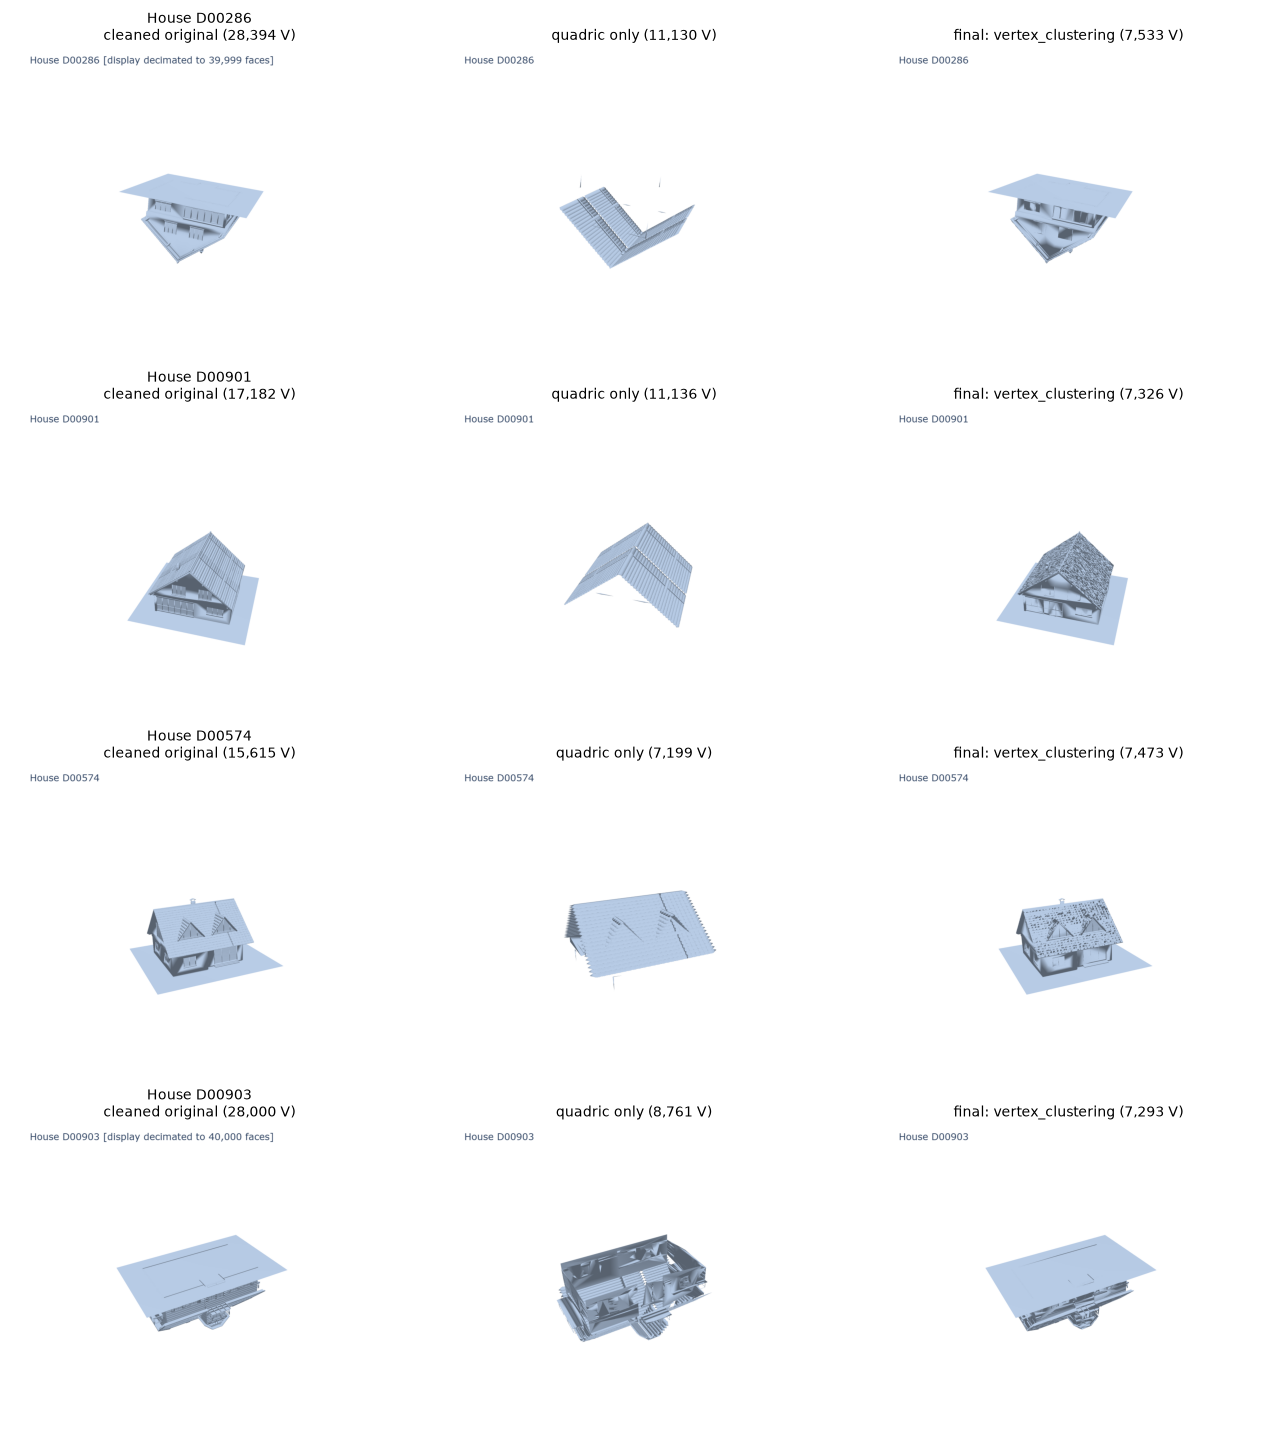

In [28]:
gallery([i for row in items[:4] for i in row], ncols=3, out=FIG / "exceptions_houses.png", cell=(4, 3.3))

**Figure 2.9.** The four House shapes: cleaned original (left), result of quadric decimation alone (centre) and final result (right).

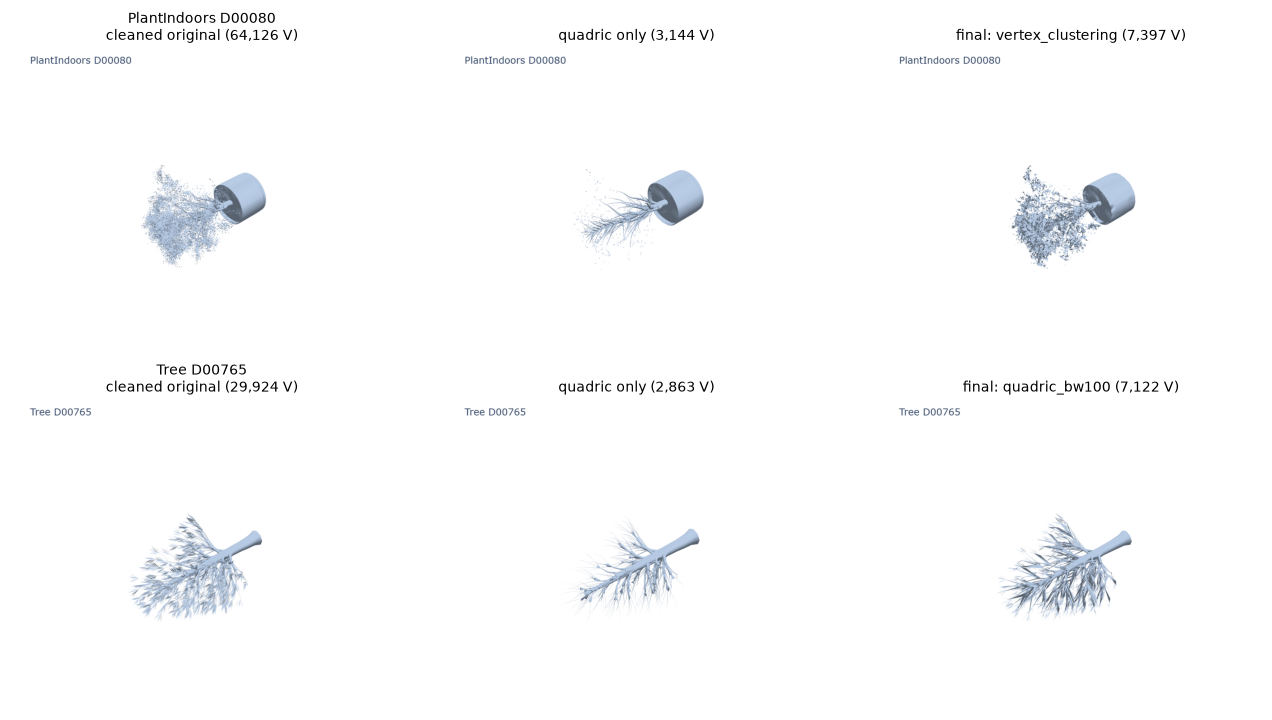

In [29]:
gallery([i for row in items[4:] for i in row], ncols=3, out=FIG / "exceptions_plant_tree.png", cell=(4, 3.3))

**Figure 2.10.** PlantIndoors D00080 and Tree D00765: cleaned original (left), result of quadric decimation alone (centre) and final
result (right).

After this change all six shapes lie inside the band (6 of 6), and none deviates by more than 4.5 % of its diagonal.
5 of them were processed by vertex clustering and 1 by quadric decimation with the increased boundary weight. The price of
vertex clustering is that the triangle sizes stay irregular; the Houses keep a large variation of their triangle areas because of the
large ground plane.

### 2.3.11  Discussion

The pipeline brings the complete database to a common sampling resolution. 100.00 % of the shapes lie in the range of 5,000 to
10,000 vertices, the mean is 7,506 vertices for a target of 7,500, and no shape was removed. Cleaning and orientation repair were
necessary for a large part of the database, and the checked decimation was necessary for a small number of shapes.

Three limitations remain. First, the uniformity of the triangles is improved by the refinement but not by the decimation or the
vertex clustering (median CV 3.43 after decimation, 3.72 for unchanged shapes). If later steps need uniform triangles,
an isotropic remeshing, for example in PyMeshLab or the PMP library, would be required; it was not used because it is fragile on
the many open and non-manifold meshes of this database. Second, 63 shapes remain inconsistently oriented, and only a minority of
the shapes is closed (Table 2.4). Descriptors that need a volume, such as compactness, convexity and rectangularity, can use
the flag `orientation_ok` and, for open shapes, a volume that is defined with the barycenter as apex or with the convex hull [3].
Third, vertices are merged only if their coordinates are identical, which is sufficient for the exact duplicates that dominate this
database.

Because remeshing changes the vertex set, the translation to the barycenter and the scaling of Section 2.5 are applied to the
resampled shapes and verified on them.

### References

[1] A. C. Telea, *Multimedia Retrieval – Assignment*, Utrecht University. https://webspace.science.uu.nl/~telea001/MR/Assignment
[2] A. C. Telea, *Technical tips, steps 1 and 2*, Multimedia Retrieval course material, Utrecht University.
[3] A. C. Telea, *Multimedia Retrieval, lecture modules 2 (Data representation), 4 (Features) and 5 (Matching)*, Utrecht University.
[4] M. Garland and P. S. Heckbert, Surface simplification using quadric error metrics, *Proc. SIGGRAPH*, 1997.
[5] Q.-Y. Zhou, J. Park and V. Koltun, Open3D: A modern library for 3D data processing, arXiv:1801.09847, 2018.
[6] J. Rossignac and P. Borrel, Multi-resolution 3D approximations for rendering complex scenes, in *Modeling in Computer Graphics*, Springer, 1993.
[7] J. W. Tukey, *Exploratory Data Analysis*, Addison-Wesley, 1977.
[8] P. Cignoni, C. Rocchini and R. Scopigno, Metro: measuring error on simplified surfaces, *Computer Graphics Forum* 17(2), 1998.

## Appendix: running Step 2 on the complete database

The following cell runs Sections 2.1 and 2.2 (scan of all shapes) and Section 2.3 (clean, orient, resample, write) on **all
2,483 shapes** and recomputes everything instead of reading saved results. It takes about 6 to 8 minutes on 8 cores and
rewrites `processed/step2_full/` (about 1.2 GB). With `RECOMPUTE = False` the saved results are loaded instead. The same
computation is available from the command line as `python src/run_step2.py --force`.

In [30]:
import time

RECOMPUTE = True        # True: recompute everything below; False: only load the saved csv results

t0 = time.time()
all_shapes = mr_stats.list_shapes()                                                   # every .obj in Data/
all_stats = mr_stats.scan_database(all_shapes, workers=8, cache_csv=DATA_OUT / "shape_stats_raw.csv",
                                   force=RECOMPUTE)                                    # Sections 2.1, 2.2
all_log = mr_resample.run_pipeline(all_stats, PROCESSED / "step2_full", workers=8,
                                   cache_csv=DATA_OUT / "resample_log_full.csv", force=RECOMPUTE)   # Section 2.3

n_written = len(list((PROCESSED / "step2_full").rglob("*.obj")))
print(f"\n{len(all_shapes)} input shapes -> {len(all_log)} processed -> {n_written} resampled files on disk  ({time.time() - t0:.0f} s)")
print("status          :", all_log.status.value_counts().to_dict())
print("actions         :", all_log.action.value_counts().to_dict())
print(f"vertices after  : mean {all_log.v_out.mean():.0f}, std {all_log.v_out.std():.0f}, "
      f"{all_log.v_out.between(5000, 10000).mean() * 100:.2f} % inside [5,000, 10,000]")
print(f"orientation_ok  : {all_log.orientation_ok.sum()} / {len(all_log)}")
assert len(all_shapes) == len(all_log) == n_written, "some shapes are missing"

scanned 2483 shapes in 80s
processed 2483 shapes in 389s

2483 input shapes -> 2483 processed -> 2483 resampled files on disk  (471 s)
status          : {'ok': 2483}
actions         : {'refined': 1754, 'kept': 367, 'decimated': 362}
vertices after  : mean 7506, std 779, 100.00 % inside [5,000, 10,000]
orientation_ok  : 2420 / 2483
